# 07 · Experimento: ventanas de rezago más largas
**Proyecto Integrador ML2 — Hacia la entrega final · Predicción de la TRM**

**Origen.** En la retroalimentación de la Entrega 2, el profesor pidió ampliar la ventana de rezagos: hoy los modelos ven el movimiento de la TRM de hace 1, 5 y 10 días, y la pregunta es si con más historia los modelos **mejoran** y **entienden mejor qué está pasando**.

**Qué se prueba.** Tres conjuntos de variables, con los mismos cuatro modelos de la Entrega 2:

| Conjunto | Variables | Qué agrega |
|---|---|---|
| `solo_trm` (referencia) | Movimiento de hace 1, 5 y 10 días | Lo de la Entrega 2 |
| `diarios_1_20` | Movimiento de **cada uno** de los últimos 20 días | Los días intermedios que hoy no se usan (lo pedido literalmente) |
| `trm_ventanas` | Referencia + **tendencia** (movimiento acumulado de 5, 10, 20 y 60 días; distancia a la media del último mes) + **volatilidad** reciente (5, 20 y 60 días) | Información de la ventana completa, que no está en ningún día suelto |

**Protocolo (el mismo de la Entrega 2, solo con el desarrollo):** validación anidada con 5 cortes walk-forward (gap 5) y búsqueda de hiperparámetros interna (`RandomizedSearchCV`, 15 combinaciones, mismos espacios). Los tres conjuntos se evalúan **sobre las mismas filas**: la ventana de 60 días necesita historia, así que se descartan las primeras 59 filas del desarrollo para todos. Por eso las cifras de `solo_trm` aquí difieren un poco de la Tabla 5 de la Entrega 2 (4.320 filas): **la comparación válida es dentro de este notebook**. Nada de lo hecho en los notebooks 01–06 cambia.

**Reglas fijadas antes de ver resultados:**
1. Se compara cada conjunto contra `solo_trm` **del mismo algoritmo, corte a corte**.
2. Un conjunto **mejora** a un algoritmo si baja el RMSE en **al menos 4 de 5 cortes y además baja el RMSE medio**; 2–3 cortes = mejora inestable; 0–1 = no mejora (la misma regla que se usó para las variables macro).
3. **El test no se abre en este notebook.** Ya se usó una vez en la Entrega 2; solo si algún conjunto cumple la regla se propondrá evaluarlo, en un paso aparte y aprobado.

**Hipótesis (escritas antes de entrenar, a partir del EDA):**
- **H7.** Los movimientos de los días 2 a 20 no mejoran a ningún algoritmo: en el EDA (E4) solo el rezago 1 es significativo; más días sueltos solo agregan ruido.
- **H8.** La tendencia no mejora: no hay memoria más allá de un día, así que el acumulado de varias semanas no anticipa el movimiento de mañana.
- **H9.** La volatilidad reciente sí contiene algo: el EDA (E10) mostró que la memoria de un día se debilita en las crisis. Un árbol puede usar esa interacción, pero la ganancia esperada es pequeña.

Una exploración rápida previa, con hiperparámetros fijos y solo con el desarrollo (fuera del repositorio), apuntó en la misma dirección; este notebook la repite con el protocolo completo.

In [1]:
import sys, time
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
from IPython.display import display

from src import config as cfg
from src.variables import agregar_ventanas
from src.validacion import cortes_walk_forward, tabla_cortes
from src.modelos import crear_modelo, evaluar_walk_forward
from src.eda import correlacion_con_ic
from src.graficos import estilo, guardar_figura, guardar_tabla, COLORES

estilo()
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
datos = pd.read_csv(cfg.DATA_PROC / "dataset.csv", parse_dates=["fecha"])
dev = datos[datos["muestra"] == "desarrollo"].reset_index(drop=True)
assert (dev["muestra"] == "desarrollo").all()          # el test no entra en este notebook
del datos
assert np.allclose(np.log(dev["trm"]).diff().iloc[1:], dev["r_trm_l1"].iloc[1:])   # filas consecutivas
ALGORITMOS = ["lineal"] + cfg.MODELOS_BOOSTING
print(f"Desarrollo: {len(dev):,} días ({dev['fecha'].min().date()} a {dev['fecha'].max().date()})")
print({c: len(v) for c, v in cfg.CONJUNTOS_VENTANAS.items()}, "variables por conjunto")

Desarrollo: 4,320 días (2003-12-17 a 2022-03-01)
{'solo_trm': 3, 'diarios_1_20': 20, 'trm_ventanas': 11} variables por conjunto


/Users/nicolas/dev/entornos/entornos/ml/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Variables nuevas y prueba anti-fuga
`agregar_ventanas` (en `src/variables.py`) calcula las variables con desplazamientos hacia atrás y ventanas que terminan en t. Se repite la prueba de perturbación del notebook 02: se alteran al azar **todos** los datos posteriores a una fecha y se recalculan las variables. Si no hay fuga, **ninguna variable anterior a esa fecha puede cambiar**; como control, las posteriores sí deben cambiar.

In [2]:
vent = agregar_ventanas(dev)
VARS_NUEVAS = sorted(set(cfg.VARS_DIARIOS + cfg.VARS_VENTANA) - set(cfg.VARS_TRM))
assert vent["r_trm_l5"].equals(dev["r_trm_l5"]) and vent["r_trm_l10"].equals(dev["r_trm_l10"])

rng = np.random.default_rng(cfg.SEMILLA)
filas = []
for corte in ["2008-10-01", "2014-11-01", "2020-03-01", "2021-06-01"]:
    alterado = dev.copy()
    futuro = alterado["fecha"] > pd.Timestamp(corte)
    alterado.loc[futuro, "trm"] *= rng.uniform(0.5, 1.5, futuro.sum())
    alterado.loc[futuro, "r_trm_l1"] = rng.normal(0, 0.01, futuro.sum())
    va = agregar_ventanas(alterado)
    antes = ~futuro
    a, b = vent.loc[antes, VARS_NUEVAS].to_numpy(), va.loc[antes, VARS_NUEVAS].to_numpy()
    c, d = vent.loc[futuro, VARS_NUEVAS].to_numpy(), va.loc[futuro, VARS_NUEVAS].to_numpy()
    filas.append({"fecha_corte": corte, "filas_antes": int(antes.sum()),
                  "valores_antes_que_cambiaron": int((~np.isclose(a, b, equal_nan=True)).sum()),
                  "valores_despues_que_cambiaron (control)": int((~np.isclose(c, d, equal_nan=True)).sum())})
pert = pd.DataFrame(filas).set_index("fecha_corte")
assert (pert["valores_antes_que_cambiaron"] == 0).all() and (pert["valores_despues_que_cambiaron (control)"] > 0).all()
guardar_tabla(pert, "tab10a_perturbacion_ventanas")
display(pert)

,filas_antes,valores_antes_que_cambiaron,valores_despues_que_cambiaron (control)
fecha_corte,,,
2008-10-01,1140,0,79323
2014-11-01,2586,0,43173
2020-03-01,3845,0,11698
2021-06-01,4142,0,4273


## 2. Filas comunes y cortes
Las tres versiones se evalúan sobre las mismas filas (las que tienen completas todas las variables) y con los mismos 5 cortes.

In [3]:
todas = sorted(set(sum(cfg.CONJUNTOS_VENTANAS.values(), [])))
base = vent.dropna(subset=todas + ["y"]).reset_index(drop=True)
assert len(base) == len(dev) - 59                      # solo se pierden las primeras 59 filas
cortes = cortes_walk_forward(len(base))
for tr, va in cortes:
    assert tr.max() + cfg.GAP < va.min()
tcortes = tabla_cortes(base["fecha"], cortes)
guardar_tabla(tcortes, "tab10b_cortes_ventanas")
print(f"Filas comunes: {len(base):,} ({base['fecha'].min().date()} a {base['fecha'].max().date()})")
display(tcortes)

Filas comunes: 4,261 (2004-03-16 a 2022-03-01)


,entrena_desde,entrena_hasta,filas_entrenamiento,valida_desde,valida_hasta,filas_validacion
corte,,,,,,
1,2004-03-16,2007-03-03,706,2007-03-13,2010-03-11,710
2,2004-03-16,2010-03-04,1416,2010-03-12,2013-03-07,710
3,2004-03-16,2013-02-28,2126,2013-03-08,2016-03-05,710
4,2004-03-16,2016-02-27,2836,2016-03-08,2019-03-07,710
5,2004-03-16,2019-02-28,3546,2019-03-08,2022-03-01,710


## 3. Validación anidada: 4 algoritmos × 3 conjuntos

In [4]:
t0 = time.perf_counter()
resultados, predicciones, hiper = {}, {}, {}
for alg in ALGORITMOS:
    for conj, variables in cfg.CONJUNTOS_VENTANAS.items():
        nombre = f"{alg} · {conj}"
        m, p, h = evaluar_walk_forward(base, variables, alg, cortes)
        resultados[nombre], predicciones[nombre], hiper[nombre] = m, p, h
print(f"Validación anidada de {len(resultados)} configuraciones: {time.perf_counter() - t0:.0f} s")

por_corte = pd.concat({k: v.set_index("corte")[["rmse_pesos", "mae_pesos", "r2_retornos"]] for k, v in resultados.items()},
                      names=["configuracion"])
guardar_tabla(por_corte, "tab10c_ventanas_por_corte")

filas = []
for alg in ALGORITMOS:
    ref = resultados[f"{alg} · solo_trm"].set_index("corte")
    for conj in cfg.CONJUNTOS_VENTANAS:
        r = resultados[f"{alg} · {conj}"].set_index("corte")
        delta = ref["rmse_pesos"] - r["rmse_pesos"]          # positivo = el conjunto baja el error
        filas.append({"algoritmo": alg, "conjunto": conj, "variables": len(cfg.CONJUNTOS_VENTANAS[conj]),
                      "rmse_media": r["rmse_pesos"].mean(), "rmse_desv": r["rmse_pesos"].std(),
                      "mae_media": r["mae_pesos"].mean(), "r2_media": r["r2_retornos"].mean(),
                      "mejora_rmse_media_pesos": delta.mean(), "cortes_que_mejora": int((delta > 0).sum())})
t10 = pd.DataFrame(filas).set_index(["algoritmo", "conjunto"])
es_ref = t10.index.get_level_values("conjunto") == "solo_trm"
t10["veredicto"] = np.where(es_ref, "referencia",
                    np.where((t10["cortes_que_mejora"] >= 4) & (t10["mejora_rmse_media_pesos"] > 0), "mejora",
                    np.where(t10["cortes_que_mejora"] >= 2, "mejora inestable", "no mejora")))
guardar_tabla(t10, "tab10_ventanas_validacion")
display(t10)

Validación anidada de 12 configuraciones: 43 s


variables  rmse_media  rmse_desv  mae_media  r2_media  \
algoritmo conjunto                                                              
lineal    solo_trm              3     20.9267     7.1686    14.8955    0.0206   
          diarios_1_20         20     21.4537     7.3768    15.2680   -0.0254   
          trm_ventanas         11     20.9809     7.2044    14.9442    0.0156   
LightGBM  solo_trm              3     20.8818     6.9704    14.9516    0.0139   
          diarios_1_20         20     20.9766     7.0081    14.9667    0.0051   
          trm_ventanas         11     20.8765     7.0434    14.9312    0.0190   
CatBoost  solo_trm              3     20.8514     7.0236    14.9271    0.0209   
          diarios_1_20         20     20.9898     7.1469    14.9504    0.0098   
          trm_ventanas         11     21.2045     7.3582    14.9909   -0.0073   
XGBoost   solo_trm              3     20.9363     6.9775    14.9874    0.0111   
          diarios_1_20         20     21.0336     7.1524    15.0176    0.0041   
          trm_ventanas         11     21.0363     7.0812    14.9640    0.0010   

                        mejora_rmse_media_pesos  cortes_que_mejora  \
algoritmo conjunto                                                   
lineal    solo_trm                       0.0000                  0   
          diarios_1_20                  -0.5270                  0   
          trm_ventanas                  -0.0542                  1   
LightGBM  solo_trm                       0.0000                  0   
          diarios_1_20                  -0.0947                  1   
          trm_ventanas                   0.0053                  3   
CatBoost  solo_trm                       0.0000                  0   
          diarios_1_20                  -0.1383                  0   
          trm_ventanas                  -0.3530                  1   
XGBoost   solo_trm                       0.0000                  0   
          diarios_1_20                  -0.0974                  2   
          trm_ventanas                  -0.1001                  1   

                               veredicto  
algoritmo conjunto                        
lineal    solo_trm            referencia  
          diarios_1_20         no mejora  
          trm_ventanas         no mejora  
LightGBM  solo_trm            referencia  
          diarios_1_20         no mejora  
          trm_ventanas  mejora inestable  
CatBoost  solo_trm            referencia  
          diarios_1_20         no mejora  
          trm_ventanas         no mejora  
XGBoost   solo_trm            referencia  
          diarios_1_20  mejora inestable  
          trm_ventanas         no mejora

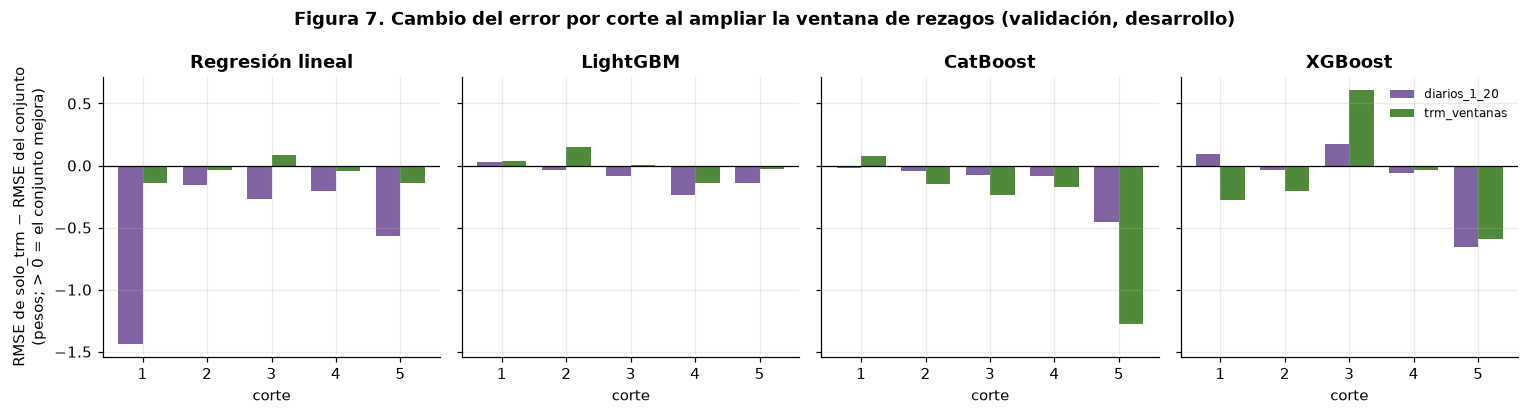

In [5]:
fig, ejes = plt.subplots(1, 4, figsize=(14, 3.8), sharey=True)
x = np.arange(1, 6)
for eje, alg in zip(ejes, ALGORITMOS):
    ref = resultados[f"{alg} · solo_trm"]["rmse_pesos"].to_numpy()
    for j, (conj, color) in enumerate([("diarios_1_20", COLORES[3]), ("trm_ventanas", COLORES[2])]):
        delta = ref - resultados[f"{alg} · {conj}"]["rmse_pesos"].to_numpy()
        eje.bar(x + (j - 0.5) * 0.38, delta, width=0.38, color=color, label=conj)
    eje.axhline(0, color="k", lw=0.8)
    eje.set(title=alg if alg != "lineal" else "Regresión lineal", xlabel="corte", xticks=x)
ejes[0].set_ylabel("RMSE de solo_trm − RMSE del conjunto\n(pesos; > 0 = el conjunto mejora)")
ejes[-1].legend(frameon=False, fontsize=8)
fig.suptitle("Figura 7. Cambio del error por corte al ampliar la ventana de rezagos (validación, desarrollo)", fontweight="bold")
fig.tight_layout()
guardar_figura(fig, "fig07_ventanas_por_corte")
plt.show()

## 4. ¿Qué está pasando? Memoria de un día según la volatilidad
El EDA (E10) mostró que la autocorrelación cae en las crisis. Aquí se mide directamente: correlación entre el movimiento de hoy y el de mañana según el tercil de volatilidad de los últimos 20 días (solo desarrollo, filas comunes).

In [6]:
base["tercil_vol20"] = pd.qcut(base["vol_trm20"], 3, labels=["baja", "media", "alta"])
filas = []
for t, g in base.groupby("tercil_vol20", observed=True):
    filas.append({"tercil_volatilidad_20d": t, "dias": len(g),
                  "volatilidad_anual_pct_media": 100 * g["vol_trm20"].mean() * np.sqrt(252),
                  **correlacion_con_ic(g["r_trm_l1"], g["y"])})
memoria = pd.DataFrame(filas).set_index("tercil_volatilidad_20d")
from scipy import stats
z_dif = (np.arctanh(memoria.loc["baja", "pearson"]) - np.arctanh(memoria.loc["alta", "pearson"])) / \
        np.sqrt(1 / (memoria.loc["baja", "dias"] - 3) + 1 / (memoria.loc["alta", "dias"] - 3))
p_dif = 2 * stats.norm.sf(abs(z_dif))
memoria["z_vs_baja"] = [0.0, np.nan, z_dif]
memoria["p_vs_baja"] = [np.nan, np.nan, p_dif]
guardar_tabla(memoria, "tab10d_memoria_por_volatilidad")
display(memoria)
print(f"Diferencia de correlaciones baja vs. alta (prueba z de Fisher): z = {z_dif:.2f}, p = {p_dif:.4f}")

,dias,volatilidad_anual_pct_media,pearson,ic95_inf,ic95_sup,spearman,z_vs_baja,p_vs_baja
tercil_volatilidad_20d,,,,,,,,
baja,1421,5.2033,0.2259,0.1759,0.2747,0.1944,0.0000,NaN
media,1420,9.2475,0.2268,0.1768,0.2755,0.2182,NaN,NaN
alta,1420,16.7386,0.1372,0.0858,0.1879,0.1530,2.4428,0.0146


Diferencia de correlaciones baja vs. alta (prueba z de Fisher): z = 2.44, p = 0.0146


### Lectura del mejor boosting con ventanas (SHAP, último corte de validación)
Se toma el boosting con menor RMSE medio en `trm_ventanas`, se reentrena con el entrenamiento del corte 5 y los hiperparámetros que eligió su búsqueda, y se explican sus predicciones en la validación de ese corte (2019–2022). Antes se verifica que es exactamente el mismo modelo de la validación.

In [7]:
cand = t10.xs("trm_ventanas", level="conjunto").drop(index="lineal")
ALG_SHAP = cand["rmse_media"].idxmin()
nombre = f"{ALG_SHAP} · trm_ventanas"
variables = cfg.CONJUNTOS_VENTANAS["trm_ventanas"]
tr, va = cortes[-1]
params = hiper[nombre].set_index("corte").loc[len(cortes)].dropna().to_dict()
params = {f"modelo__{k}": (int(v) if float(v).is_integer() and k not in ("subsample", "colsample_bytree", "rsm",
          "learning_rate", "reg_lambda", "l2_leaf_reg") else v) for k, v in params.items()}
modelo = crear_modelo(ALG_SHAP).set_params(**params).fit(base.loc[tr, variables], base.loc[tr, "y"])
X_va = base.loc[va, variables]
pn = predicciones[nombre]
p5 = pn.loc[pn["corte"] == len(cortes), "yhat"].to_numpy()
assert np.allclose(modelo.predict(X_va), p5)            # es el mismo modelo de la validación
valores = shap.TreeExplainer(modelo.named_steps["modelo"]).shap_values(X_va)
imp = pd.DataFrame({"importancia_media_abs": np.abs(valores).mean(axis=0)}, index=variables)
imp["importancia_pct"] = 100 * imp["importancia_media_abs"] / imp["importancia_media_abs"].sum()
imp = imp.sort_values("importancia_media_abs", ascending=False)
guardar_tabla(imp, "tab10e_shap_ventanas")
print(f"{nombre} · corte 5 · {params}")
display(imp)

LightGBM · trm_ventanas · corte 5 · {'modelo__subsample': 0.6, 'modelo__reg_lambda': 1.0, 'modelo__num_leaves': 31, 'modelo__n_estimators': 200, 'modelo__min_child_samples': 200, 'modelo__max_depth': 2, 'modelo__learning_rate': 0.03, 'modelo__colsample_bytree': 0.8}


,importancia_media_abs,importancia_pct
r_trm_l1,0.0012,52.8864
r_trm_l10,0.0002,8.2941
r_trm_acum20,0.0002,7.9048
vol_trm20,0.0001,5.7473
r_trm_acum10,0.0001,4.9071
r_trm_acum60,0.0001,4.6281
r_trm_acum5,0.0001,4.2404
r_trm_l5,0.0001,3.1753
dist_media20,0.0001,3.1017
vol_trm5,0.0001,2.9528


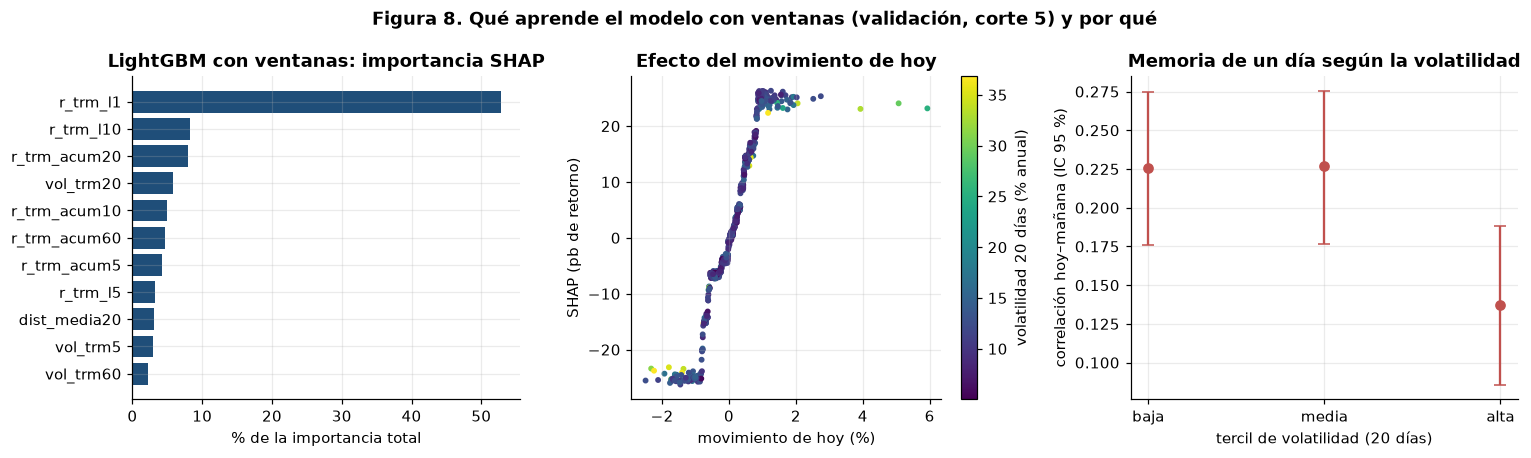

In [8]:
fig, ejes = plt.subplots(1, 3, figsize=(14, 4.2))
ejes[0].barh(imp.index[::-1], imp["importancia_pct"][::-1], color=COLORES[0])
ejes[0].set(title=f"{ALG_SHAP} con ventanas: importancia SHAP", xlabel="% de la importancia total")
i1 = variables.index("r_trm_l1")
sc = ejes[1].scatter(100 * X_va["r_trm_l1"], 1e4 * valores[:, i1], c=100 * np.sqrt(252) * X_va["vol_trm20"],
                     cmap="viridis", s=8)
fig.colorbar(sc, ax=ejes[1], label="volatilidad 20 días (% anual)")
ejes[1].set(title="Efecto del movimiento de hoy", xlabel="movimiento de hoy (%)", ylabel="SHAP (pb de retorno)")
m = memoria
ejes[2].errorbar(range(3), m["pearson"], yerr=[m["pearson"] - m["ic95_inf"], m["ic95_sup"] - m["pearson"]],
                 fmt="o", color=COLORES[1], capsize=4)
ejes[2].set(title="Memoria de un día según la volatilidad", xticks=range(3), xticklabels=m.index,
            xlabel="tercil de volatilidad (20 días)", ylabel="correlación hoy–mañana (IC 95 %)")
fig.suptitle("Figura 8. Qué aprende el modelo con ventanas (validación, corte 5) y por qué", fontweight="bold")
fig.tight_layout()
guardar_figura(fig, "fig08_ventanas_interpretacion")
plt.show()

## 5. Contraste de hipótesis

In [9]:
def veredictos(conj):
    """Resume en una línea el veredicto de un conjunto para los cuatro algoritmos.

    Parámetros
    ----------
    conj : str
        Conjunto de variables ("diarios_1_20" o "trm_ventanas").

    Devuelve
    --------
    str
        Por algoritmo: veredicto, cortes en que mejora y mejora media del RMSE en pesos.
    """
    return ", ".join(f"{a}: {t10.loc[(a, conj), 'veredicto']} ({int(t10.loc[(a, conj), 'cortes_que_mejora'])}/5, "
                     f"{t10.loc[(a, conj), 'mejora_rmse_media_pesos']:+.3f})" for a in ALGORITMOS)

vol_imp = imp.loc[[v for v in imp.index if v.startswith("vol_")], "importancia_pct"].sum()
tend_imp = imp.loc[[v for v in imp.index if v.startswith("r_trm_acum") or v == "dist_media20"], "importancia_pct"].sum()
hip = pd.DataFrame([
    ["H7", "Los movimientos de los días 2 a 20 no mejoran a ningún algoritmo", veredictos("diarios_1_20")],
    ["H8 + H9", "Las ventanas (tendencia y volatilidad) no mejoran de forma confiable; si algo aporta, es la volatilidad",
     veredictos("trm_ventanas") + f". SHAP de {ALG_SHAP}: volatilidad {vol_imp:.0f} %, tendencia {tend_imp:.0f} %"],
    ["H9 (mecanismo)", "La memoria de un día se debilita cuando la volatilidad es alta",
     "Correlación hoy–mañana: " + ", ".join(f"{t} {r:.3f}" for t, r in memoria["pearson"].items())],
], columns=["hipotesis", "enunciado", "evidencia"]).set_index("hipotesis")
guardar_tabla(hip, "tab10f_hipotesis_ventanas")
display(hip)

,enunciado,evidencia
hipotesis,,
H7,Los movimientos de los días 2 a 20 no mejoran ...,"lineal: no mejora (0/5, -0.527), LightGBM: no ..."
H8 + H9,Las ventanas (tendencia y volatilidad) no mejo...,"lineal: no mejora (1/5, -0.054), LightGBM: mej..."
H9 (mecanismo),La memoria de un día se debilita cuando la vol...,"Correlación hoy–mañana: baja 0.226, media 0.22..."


## 6. Conclusión
**Ampliar la ventana de rezagos no mejora la predicción.** Ningún conjunto cumple la regla fijada en ningún algoritmo, así que **el test no se abre y el modelo final no cambia**.

**Lo que muestran la Tabla 10 y la Figura 7** (mejora media del RMSE frente a `solo_trm`, en pesos; positivo = mejora):
- **`diarios_1_20` empeora a los cuatro algoritmos en promedio:** regresión lineal −0,53, LightGBM −0,09, CatBoost −0,14 y XGBoost −0,10. **H7 confirmada.** XGBoost queda como "mejora inestable" por la regla (mejora en 2 de 5 cortes), pero en promedio empeora. Es lo que anticipaba el EDA (E4): los movimientos de los días 2 a 20 no tienen memoria, así que agregar 17 variables solo agrega ruido. La regresión lineal es la que más sufre (−1,44 pesos en el corte 1, la crisis de 2008), porque estima un coeficiente para cada una.
- **`trm_ventanas` tampoco mejora:** LightGBM baja el error en 3 de 5 cortes, pero en promedio solo 0,005 pesos (medio centavo): un empate. CatBoost empeora 0,35, XGBoost 0,10 y la lineal 0,05. **H8 confirmada.** El peor corte es el 5 (2019–2022, COVID y choque petrolero), donde CatBoost pierde 1,28 pesos: los patrones de tendencia aprendidos en periodos más tranquilos no se repiten cuando el mercado cambia.

**Qué está pasando (Figura 8):**
1. **El modelo sigue apoyándose en el movimiento de hoy.** En LightGBM con ventanas, `r_trm_l1` concentra el 53 % de la importancia SHAP. Las variables de tendencia se llevan cerca del 25 % y las de volatilidad cerca del 11 %, **pero no bajan el error**: el modelo las usa para ajustar ruido del entrenamiento que no se repite en la validación.
2. **El efecto del movimiento de hoy tiene forma de S:** es proporcional entre −1 % y +1 % y se vuelve plano por fuera. Un movimiento grande no se repite en proporción al día siguiente. Esto lo capta el boosting y no la regresión lineal, pero esos días son pocos y la ganancia en el error es mínima.
3. **La memoria de un día se debilita cuando el mercado está agitado:** la correlación hoy–mañana es 0,23 con volatilidad baja o media y 0,14 con volatilidad alta, una diferencia significativa (prueba z de Fisher, z = 2,44, p = 0,015). **H9 confirmada como mecanismo.** Aun así, el modelo no la convierte en menor error: en los periodos agitados el error lo dominan movimientos grandes que nadie anticipa, y ajustar cuánto se repite el movimiento de hoy cambia la predicción en fracciones de peso.

**Respuesta al profesor.** Ampliamos la ventana de dos formas: con cada uno de los últimos 20 días y con resúmenes de la ventana (tendencia y volatilidad). Con el mismo protocolo de la Entrega 2, ninguna mejora el error. La razón es de fondo: **la TRM diaria solo tiene memoria de un día** (porque es el promedio de las operaciones del día), **esa memoria es más débil en épocas turbulentas y para los movimientos grandes**, y más historia no agrega información sobre el día siguiente.

## Qué llevar al informe final
- **Figura 7** (`fig07_ventanas_por_corte.png`) y **Tabla 10** (`tab10_ventanas_validacion.csv`): ampliar la ventana no mejora; se descarta con la misma regla de la Entrega 2.
- **Figura 8** (`fig08_ventanas_interpretacion.png`) y **Tabla 10d** (`tab10d_memoria_por_volatilidad.csv`): la interpretación. Solo se predice la continuación de un día, más débil en las crisis y en los movimientos grandes (sección 8.2, interpretación; sección 8.4, limitaciones).
- **Tabla 10a** (`tab10a_perturbacion_ventanas.csv`): las variables nuevas pasan la prueba anti-fuga.